In [1]:
"""
NOTEBOOK 2B.1 - Perturbation Test (Fase 2B Faithfulness Quick Check)
IndoMeme-XAI

Untuk tiap metode XAI:
  mask top-K% feature paling penting -> forward -> ukur drop performance
Random masking sebagai kontrol. Faithful jika delta_xai > delta_random.
"""

from pathlib import Path

KAGGLE_INPUT = Path("/kaggle/input/datasets/reynaldaryansyah")
ROOT_DIR     = KAGGLE_INPUT / "xai-dataset" / "data" / "data"
CSV_PATH     = ROOT_DIR / "processed" / "all_splits.csv"
IMG_DIR      = ROOT_DIR / "images"
CKPT_PATH    = Path("/kaggle/input/datasets/reynaldaryansyah/xai-dataset/exp-1b9-ensemble/model_seed7.pt")

# Path attribution arrays dari Fase 2A. Sesuaikan dengan dataset Kaggle yg sudah di-mount.
ATTR_PATHS = {
    "ig_text":     Path("/kaggle/input/datasets/reynaldaryansyah/xai-2a1-ig/xai_2A1_integrated_gradients/ig_attributions.npz"),
    "cross_attn":  Path("/kaggle/input/datasets/reynaldaryansyah/xai-2a2-cross-attn/xai_2A2_cross_attention/cross_attn_maps.npz"),
    "rollout":     Path("/kaggle/input/datasets/reynaldaryansyah/xai-2a3-rollout/xai_2A3_attention_rollout/rollout_maps.npz"),
    "incongruity": Path("/kaggle/input/datasets/reynaldaryansyah/xai-2a4-incongruity/xai_2A4_incongruity_heatmap/incongruity_maps.npz"),
}

OUTPUT_DIR = Path("/kaggle/working/xai_2B1_perturbation")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

CONFIG = dict(
    exp_id           = "2B.1_perturbation_test",
    seed             = 42,

    text_model_name  = "indolem/indobertweet-base-uncased",
    image_model_name = "google/vit-base-patch16-224-in21k",
    freeze_n_layers  = 4,
    topic_emb_dim    = 32,
    head_hidden      = 256,
    dropout          = 0.3,
    icam_num_heads   = 8,
    icam_dropout     = 0.1,
    supcon_proj_hidden  = 128,
    supcon_proj_out     = 128,
    max_seq_len      = 128,
    batch_size       = 16,
    grid_size        = 14,
    img_size         = 224,
    patch_size       = 16,           # 224 / 14 = 16 px per patch

    # Masking levels
    mask_levels      = [0.10, 0.20, 0.30],
)

print(f"Experiment: {CONFIG['exp_id']}")
print(f"Mask levels: {CONFIG['mask_levels']}")

Experiment: 2B.1_perturbation_test
Mask levels: [0.1, 0.2, 0.3]


In [2]:
import os, json, random, time, math, re, unicodedata
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torch.amp import autocast

from PIL import Image
import matplotlib.pyplot as plt
from torchvision import transforms
from transformers import AutoTokenizer, AutoModel, ViTImageProcessor, ViTModel
from sklearn.metrics import f1_score, accuracy_score, recall_score, precision_score
from tqdm.auto import tqdm

def set_seed(seed: int):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(CONFIG["seed"])
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device: {DEVICE}")

Device: cuda


In [3]:
SLANG_DICT = {
    "gw":"saya","gue":"saya","gua":"saya","guwe":"saya",
    "lu":"kamu","lo":"kamu","loe":"kamu","elo":"kamu","elu":"kamu",
    "ane":"saya","ente":"kamu","agan":"kamu","sis":"kakak",
    "bro":"kawan","bray":"kawan","bre":"kawan","cuy":"kawan",
    "klian":"kalian","kmu":"kamu","kamuh":"kamu",
    "aq":"aku","akoh":"aku","akuh":"aku",
    "gak":"tidak","ga":"tidak","gk":"tidak","nggak":"tidak",
    "ngga":"tidak","ngk":"tidak","kgk":"tidak","tdk":"tidak",
    "engga":"tidak","enggak":"tidak","kga":"tidak",
    "yg":"yang","dgn":"dengan","dg":"dengan","krn":"karena",
    "krna":"karena","utk":"untuk","tp":"tapi","tpi":"tapi",
    "klo":"kalau","klau":"kalau","kl":"kalau","klu":"kalau",
    "spy":"supaya","ato":"atau",
    "bgt":"banget","bgtt":"banget","bngt":"banget",
    "bnr":"benar","bener":"benar",
    "emg":"memang","emang":"memang","mmg":"memang",
    "skrg":"sekarang","skrng":"sekarang",
    "td":"tadi","tdi":"tadi","bsk":"besok",
    "knp":"kenapa","gmn":"bagaimana","gimana":"bagaimana",
    "gmana":"bagaimana","kyk":"seperti","kayak":"seperti","kek":"seperti",
    "udh":"sudah","udah":"sudah","uda":"sudah","dah":"sudah",
    "blm":"belum","blom":"belum",
    "lg":"lagi","lgi":"lagi","msh":"masih","msi":"masih",
    "jd":"jadi","jdi":"jadi",
    "tau":"tahu","taw":"tahu","tw":"tahu",
    "liat":"lihat","ngeliat":"melihat","denger":"dengar",
    "ngomong":"bicara","blng":"bilang","bilg":"bilang",
    "aja":"saja","doang":"saja","doank":"saja",
    "sih":"","deh":"","dong":"","kok":"","lah":"",
    "loh":"","lho":"","yah":"",
    "iy":"iya","iyaa":"iya","iye":"iya","yup":"iya","yoi":"iya",
    "org":"orang","orng":"orang","orgnya":"orangnya",
    "dr":"dari","dri":"dari","kpd":"kepada",
    "thd":"terhadap","ttg":"tentang",
    "abis":"habis","trs":"terus","trus":"terus",
    "tmn":"teman","temen":"teman","tman":"teman",
    "rmh":"rumah","kntr":"kantor","krj":"kerja",
    "ank":"anak","indo":"indonesia",
    "cwo":"cowok","cwe":"cewek","cwok":"cowok","cwek":"cewek",
    "wkwk":"haha","wkwkwk":"haha","wkwkwkwk":"haha","wkwkwkwkwk":"haha",
    "hahaha":"haha","hahahaha":"haha",
    "hehehe":"hehe","hehehehe":"hehe",
    "anjir":"anjing","anjay":"anjing","anjrit":"anjing",
    "anjr":"anjing","anying":"anjing","njir":"anjing",
    "bgsd":"bangsat","bgst":"bangsat",
    "bjir":"anjing","bjg":"bajingan",
    "kntl":"kontol","mmk":"memek","tai":"tahi",
}

URL_PATTERN     = re.compile(r"(https?://\S+|www\.\S+|\S+\.(?:com|co\.id|net|org|id|tv|me)\b\S*)", re.IGNORECASE)
MENTION_PATTERN = re.compile(r"@\w+")
HASHTAG_PATTERN = re.compile(r"#(\w+)")
ALLOWED_PUNCT   = re.compile(r"[^\w\s\.,!?\-'\"]+", re.UNICODE)
MULTI_SPACE     = re.compile(r"\s+")
SEP_TOKEN = "[SEP]"

def _normalize_unicode(t): return unicodedata.normalize("NFKC", t)
def _normalize_slang(text):
    out = []
    for tok in text.split():
        prefix, suffix, core = "", "", tok
        while core and not core[0].isalnum(): prefix += core[0]; core = core[1:]
        while core and not core[-1].isalnum(): suffix = core[-1] + suffix; core = core[:-1]
        out.append(f"{prefix}{SLANG_DICT.get(core.lower(), core)}{suffix}")
    return " ".join(out)
def clean_ocr(text):
    if text is None: return ""
    if isinstance(text, float) and pd.isna(text): return ""
    text = _normalize_unicode(str(text)).lower()
    text = URL_PATTERN.sub(" ", text); text = MENTION_PATTERN.sub(" ", text)
    text = HASHTAG_PATTERN.sub(r"\1", text); text = ALLOWED_PUNCT.sub(" ", text)
    text = _normalize_slang(text)
    return MULTI_SPACE.sub(" ", text).strip()
def _safe_str(x):
    if x is None: return ""
    if isinstance(x, float) and pd.isna(x): return ""
    return str(x).strip()
def format_input(topic, caption, ocr_cleaned, sep=SEP_TOKEN):
    if topic is None or (isinstance(topic, float) and pd.isna(topic)):
        topic_str = "unknown"
    elif isinstance(topic, (list, tuple, set)):
        items = sorted({str(t).lower().strip() for t in topic if t})
        topic_str = ",".join(items) if items else "unknown"
    else:
        topic_str = str(topic).lower().strip() or "unknown"
    return f"[{topic_str}] {_safe_str(caption)} {sep} {_safe_str(ocr_cleaned)}".strip()

In [4]:
df = pd.read_csv(CSV_PATH)
df["label"] = df["hate_final"].map({"not hate": 0, "hate": 1})
df["ocr_cleaned"] = df["ocr"].apply(clean_ocr)
df["text_input"]  = df.apply(lambda r: format_input(r["topic"], r["caption"], r["ocr_cleaned"]), axis=1)

def resolve_image_path(row):
    raw = row.get("local_image_path") or row.get("image_path")
    if raw is None or (isinstance(raw, float) and pd.isna(raw)): return None
    fname = Path(str(raw).replace("\\","/")).name
    return str(IMG_DIR / row["split"] / fname)
df["full_image_path"] = df.apply(resolve_image_path, axis=1)

TOPIC_LIST = ["political","national origin","individual","institutions",
              "gender","religion","social sub-groups","unknown"]
TOPIC2IDX = {t: i for i, t in enumerate(TOPIC_LIST)}
N_TOPICS  = len(TOPIC_LIST)

def topic_to_multihot(topic):
    vec = np.zeros(N_TOPICS, dtype=np.float32)
    if topic is None or (isinstance(topic, float) and pd.isna(topic)):
        vec[TOPIC2IDX["unknown"]] = 1.0; return vec
    parts = [p.strip().lower() for p in str(topic).split(",") if p.strip()]
    found = False
    for p in parts:
        if p in TOPIC2IDX: vec[TOPIC2IDX[p]] = 1.0; found = True
    if not found: vec[TOPIC2IDX["unknown"]] = 1.0
    return vec

df["topic_multihot"] = df["topic"].apply(topic_to_multihot)
df_test = df[df["split"] == "test"].copy().reset_index(drop=True)
print(f"Test samples: {len(df_test)}")

Test samples: 1005


In [5]:
tokenizer       = AutoTokenizer.from_pretrained(CONFIG["text_model_name"])
image_processor = ViTImageProcessor.from_pretrained(CONFIG["image_model_name"])
IMG_MEAN = image_processor.image_mean
IMG_STD  = image_processor.image_std

EVAL_TRANSFORM = transforms.Compose([
    transforms.Resize((CONFIG["img_size"], CONFIG["img_size"])),
    transforms.ToTensor(),
    transforms.Normalize(mean=IMG_MEAN, std=IMG_STD),
])

class IndoMemeDataset(Dataset):
    def __init__(self, df_split, tokenizer, transform, max_seq_len=128):
        self.df = df_split.reset_index(drop=True)
        self.tokenizer = tokenizer; self.transform = transform; self.max_seq_len = max_seq_len
    def __len__(self): return len(self.df)
    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        img = Image.open(row["full_image_path"]).convert("RGB")
        img_tensor = self.transform(img)
        enc = self.tokenizer(row["text_input"], padding="max_length", truncation=True,
                             max_length=self.max_seq_len, return_tensors="pt")
        return {
            "input_ids":      enc["input_ids"].squeeze(0),
            "attention_mask": enc["attention_mask"].squeeze(0),
            "pixel_values":   img_tensor,
            "topic":          torch.from_numpy(row["topic_multihot"]),
            "label":          torch.tensor(int(row["label"]), dtype=torch.long),
            "idx":            int(row["idx"]),
        }

ds_test = IndoMemeDataset(df_test, tokenizer, EVAL_TRANSFORM, CONFIG["max_seq_len"])
dl_test = DataLoader(ds_test, batch_size=CONFIG["batch_size"], shuffle=False, num_workers=2, pin_memory=True)
print(f"Test loader: {len(dl_test)} batches")

config.json: 0.00B [00:00, ?B/s]

tokenizer_config.json:   0%|          | 0.00/2.00 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

preprocessor_config.json:   0%|          | 0.00/160 [00:00<?, ?B/s]

Test loader: 63 batches


In [6]:
class ICAMFusion(nn.Module):
    def __init__(self, hidden_dim=768, num_heads=8, dropout=0.1):
        super().__init__()
        self.t2i_attn = nn.MultiheadAttention(hidden_dim, num_heads, dropout=dropout, batch_first=True)
        self.i2t_attn = nn.MultiheadAttention(hidden_dim, num_heads, dropout=dropout, batch_first=True)
        self.gate_relevant    = nn.Linear(2 * hidden_dim, hidden_dim)
        self.gate_incongruent = nn.Linear(2 * hidden_dim, hidden_dim)
        self.fusion_proj = nn.Linear(hidden_dim, hidden_dim)
        self.layer_norm  = nn.LayerNorm(hidden_dim)

    def forward(self, text_h, image_h, text_mask=None):
        text_kpm = (~text_mask.bool()) if text_mask is not None else None
        t2i_out, _ = self.t2i_attn(text_h, image_h, image_h, key_padding_mask=None, need_weights=False)
        i2t_out, _ = self.i2t_attn(image_h, text_h, text_h, key_padding_mask=text_kpm, need_weights=False)
        h_image_pooled = i2t_out.mean(dim=1)
        text_norm  = F.normalize(text_h,  dim=-1)
        image_norm = F.normalize(image_h, dim=-1)
        sim         = torch.bmm(text_norm, image_norm.transpose(1, 2))
        incongruity = 1.0 - sim.abs()
        inc_w       = F.softmax(incongruity, dim=-1)
        h_inc       = torch.bmm(inc_w, image_h)
        if text_mask is not None:
            m = text_mask.unsqueeze(-1).float()
            h_inc_pooled = (h_inc * m).sum(dim=1) / m.sum(dim=1).clamp(min=1.0)
        else:
            h_inc_pooled = h_inc.mean(dim=1)
        h_text = text_h[:, 0]
        g1 = torch.sigmoid(self.gate_relevant(   torch.cat([h_text, h_image_pooled], dim=-1)))
        g2 = torch.sigmoid(self.gate_incongruent(torch.cat([h_text, h_inc_pooled  ], dim=-1)))
        fused   = h_text + g1 * h_image_pooled + g2 * h_inc_pooled
        return self.layer_norm(self.fusion_proj(fused)), g1.mean().item(), g2.mean().item()


class ICAMHateModelSupCon(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.text_encoder  = AutoModel.from_pretrained(cfg["text_model_name"])
        self.image_encoder = ViTModel.from_pretrained(cfg["image_model_name"])
        for p in self.text_encoder.parameters():  p.requires_grad = False
        for p in self.image_encoder.parameters(): p.requires_grad = False
        hidden = self.text_encoder.config.hidden_size
        self.icam = ICAMFusion(hidden_dim=hidden, num_heads=cfg["icam_num_heads"], dropout=cfg["icam_dropout"])
        self.supcon_proj = nn.Sequential(
            nn.Linear(hidden, cfg["supcon_proj_hidden"]),
            nn.ReLU(),
            nn.Linear(cfg["supcon_proj_hidden"], cfg["supcon_proj_out"]),
        )
        self.topic_proj = nn.Sequential(nn.Linear(N_TOPICS, cfg["topic_emb_dim"]), nn.GELU())
        head_in = hidden + cfg["topic_emb_dim"]
        self.head = nn.Sequential(
            nn.Linear(head_in, cfg["head_hidden"]), nn.GELU(),
            nn.Dropout(cfg["dropout"]), nn.Linear(cfg["head_hidden"], 2),
        )

    def forward(self, input_ids, attention_mask, pixel_values, topic):
        t_out = self.text_encoder(input_ids=input_ids, attention_mask=attention_mask)
        i_out = self.image_encoder(pixel_values=pixel_values)
        h_fused, g1m, g2m = self.icam(t_out.last_hidden_state, i_out.last_hidden_state, attention_mask)
        topic_emb = self.topic_proj(topic)
        return self.head(torch.cat([h_fused, topic_emb], dim=-1))

model = ICAMHateModelSupCon(CONFIG).to(DEVICE)
ckpt = torch.load(CKPT_PATH, map_location=DEVICE)
state = ckpt["state_dict"] if (isinstance(ckpt, dict) and "state_dict" in ckpt) else ckpt
missing, unexpected = model.load_state_dict(state, strict=False)
for p in model.parameters(): p.requires_grad = False
model.eval()
print(f"Model loaded. Missing={len(missing)}, Unexpected={len(unexpected)}")

pytorch_model.bin:   0%|          | 0.00/445M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

BertModel LOAD REPORT from: indolem/indobertweet-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.decoder.weight             | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.decoder.bias               | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


model.safetensors:   0%|          | 0.00/445M [00:00<?, ?B/s]

config.json:   0%|          | 0.00/502 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/346M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

Model loaded. Missing=0, Unexpected=0


In [7]:
attr = {}

# IG (text)
ig_data = np.load(ATTR_PATHS["ig_text"])
attr["ig_text"] = {
    "token_l2":   ig_data["token_l2"],            # [N, 128]
    "att_mask":   ig_data["attention_mask"],      # [N, 128]
    "idxs":       ig_data["idxs"],                # [N]
}
print(f"IG text     : {attr['ig_text']['token_l2'].shape}")

# Image methods (3): semua [N, 14, 14]
for name, key_in_npz in [
    ("cross_attn",  "maps_14x14"),
    ("rollout",     "maps_14x14"),
    ("incongruity", "maps_softmax_14x14"),       # pakai softmax (faithful)
]:
    data = np.load(ATTR_PATHS[name])
    attr[name] = {
        "maps_14x14": data[key_in_npz],
        "idxs":       data["idxs"],
    }
    print(f"{name:12s}: {attr[name]['maps_14x14'].shape}")

# Verify ordering konsisten antar metode
ref_idxs = attr["ig_text"]["idxs"]
for name in ["cross_attn", "rollout", "incongruity"]:
    assert np.array_equal(ref_idxs, attr[name]["idxs"]), f"idx mismatch di {name}!"
print("All idxs konsisten across methods.")

IG text     : (1005, 128)
cross_attn  : (1005, 14, 14)
rollout     : (1005, 14, 14)
incongruity : (1005, 14, 14)
All idxs konsisten across methods.


In [8]:
def mask_text_batch(input_ids, attention_mask, token_l2_batch, mask_ratio,
                     special_token_ids=None, mask_strategy="zero_attn"):
    """
    Mask top-K% tokens berdasarkan token_l2 score (per sample).

    Parameters
    ----------
    input_ids       : [B, T] tensor
    attention_mask  : [B, T] tensor (1=real, 0=pad)
    token_l2_batch  : [B, T] np.ndarray - skor IG per token
    mask_ratio      : float, e.g., 0.20 (mask 20% top tokens)
    special_token_ids: set of ids untuk skip (CLS, SEP, PAD, UNK)
    mask_strategy   : "zero_attn" -> attention_mask = 0 di posisi mask
                      "pad_token" -> ganti ke PAD token

    Returns
    -------
    new_input_ids, new_attention_mask
    """
    if special_token_ids is None:
        special_token_ids = {tokenizer.cls_token_id, tokenizer.sep_token_id,
                              tokenizer.pad_token_id, tokenizer.unk_token_id}

    B, T = input_ids.shape
    new_ids  = input_ids.clone()
    new_mask = attention_mask.clone()

    for b in range(B):
        # Cari token kandidat (real, non-special)
        is_real_b = attention_mask[b].cpu().numpy() == 1
        is_special_b = np.array([int(t) in special_token_ids for t in input_ids[b].cpu().numpy()])
        eligible = is_real_b & ~is_special_b
        scores = token_l2_batch[b].copy()
        scores[~eligible] = -np.inf

        n_eligible = int(eligible.sum())
        n_mask = max(1, int(round(n_eligible * mask_ratio)))
        if n_mask >= n_eligible: continue

        top_idx = np.argpartition(-scores, n_mask)[:n_mask]

        if mask_strategy == "zero_attn":
            new_mask[b, top_idx] = 0
        elif mask_strategy == "pad_token":
            new_ids[b, top_idx] = tokenizer.pad_token_id
            new_mask[b, top_idx] = 0
        else:
            raise ValueError(mask_strategy)

    return new_ids, new_mask

In [9]:
def mask_image_batch(pixel_values, attn_maps_14x14_batch, mask_ratio,
                     mask_strategy="zero"):
    """
    Mask top-K% patches berdasarkan attribution map (per sample).

    Parameters
    ----------
    pixel_values            : [B, 3, 224, 224] tensor (sudah normalized)
    attn_maps_14x14_batch   : [B, 14, 14] np.ndarray
    mask_ratio              : float
    mask_strategy           : "zero" -> set patch ke 0 (= image_mean stlh normalize)
                               "noise" -> Gaussian noise

    Returns
    -------
    new_pixel_values
    """
    B = pixel_values.size(0)
    new_pv = pixel_values.clone()
    G = CONFIG["grid_size"]
    P = CONFIG["patch_size"]
    n_patches_total = G * G
    n_mask = max(1, int(round(n_patches_total * mask_ratio)))

    for b in range(B):
        flat = attn_maps_14x14_batch[b].flatten()
        top_idx = np.argpartition(-flat, n_mask)[:n_mask]
        rows = top_idx // G
        cols = top_idx %  G

        for r, c in zip(rows, cols):
            r0, r1 = int(r) * P, (int(r) + 1) * P
            c0, c1 = int(c) * P, (int(c) + 1) * P
            if mask_strategy == "zero":
                new_pv[b, :, r0:r1, c0:c1] = 0.0    # = image mean stlh normalize
            elif mask_strategy == "noise":
                new_pv[b, :, r0:r1, c0:c1] = torch.randn(3, P, P, device=pixel_values.device)
    return new_pv


def mask_image_batch_random(pixel_values, mask_ratio, rng_seed=0):
    """Random patch masking, untuk baseline kontrol."""
    B = pixel_values.size(0)
    new_pv = pixel_values.clone()
    G = CONFIG["grid_size"]; P = CONFIG["patch_size"]
    n_patches_total = G * G
    n_mask = max(1, int(round(n_patches_total * mask_ratio)))
    rng = np.random.RandomState(rng_seed)
    for b in range(B):
        idx = rng.choice(n_patches_total, size=n_mask, replace=False)
        rows, cols = idx // G, idx % G
        for r, c in zip(rows, cols):
            r0, r1 = int(r) * P, (int(r) + 1) * P
            c0, c1 = int(c) * P, (int(c) + 1) * P
            new_pv[b, :, r0:r1, c0:c1] = 0.0
    return new_pv


def mask_text_batch_random(input_ids, attention_mask, mask_ratio, rng_seed=0,
                            special_token_ids=None):
    """Random token masking."""
    if special_token_ids is None:
        special_token_ids = {tokenizer.cls_token_id, tokenizer.sep_token_id,
                              tokenizer.pad_token_id, tokenizer.unk_token_id}
    B, T = input_ids.shape
    new_mask = attention_mask.clone()
    rng = np.random.RandomState(rng_seed)
    for b in range(B):
        is_real = attention_mask[b].cpu().numpy() == 1
        is_special = np.array([int(t) in special_token_ids for t in input_ids[b].cpu().numpy()])
        eligible = np.where(is_real & ~is_special)[0]
        n_mask = max(1, int(round(len(eligible) * mask_ratio)))
        if n_mask >= len(eligible): continue
        idx = rng.choice(eligible, size=n_mask, replace=False)
        new_mask[b, idx] = 0
    return input_ids, new_mask

In [10]:
@torch.no_grad()
def eval_with_mask(model, loader, attribution_dict=None, mask_ratio=0.0,
                   mask_target="text", mask_strategy=None, random_seed=42):
    """
    Evaluate model di test set dgn opsional masking.

    mask_target : "text" | "image" | "random_text" | "random_image" | None (no mask)
    attribution_dict : dict berisi token_l2 (utk text) atau maps_14x14 (utk image),
                        di-index per-batch via "idxs" array
    """
    model.eval()
    all_logits, all_labels, all_idxs = [], [], []
    g_rng = random_seed
    for batch_i, batch in enumerate(tqdm(loader, leave=False)):
        input_ids      = batch["input_ids"].to(DEVICE)
        attention_mask = batch["attention_mask"].to(DEVICE)
        pixel_values   = batch["pixel_values"].to(DEVICE)
        topic          = batch["topic"].to(DEVICE)
        idxs_b         = batch["idx"].cpu().numpy()

        # Apply masking
        if mask_target == "text":
            # Get token_l2 for these idxs
            global_idxs = attribution_dict["idxs"]
            order = [np.where(global_idxs == i)[0][0] for i in idxs_b]
            tl2 = attribution_dict["token_l2"][order]
            input_ids, attention_mask = mask_text_batch(
                input_ids, attention_mask, tl2, mask_ratio,
                mask_strategy=mask_strategy or "zero_attn"
            )
        elif mask_target == "random_text":
            input_ids, attention_mask = mask_text_batch_random(
                input_ids, attention_mask, mask_ratio, rng_seed=g_rng + batch_i
            )
        elif mask_target == "image":
            global_idxs = attribution_dict["idxs"]
            order = [np.where(global_idxs == i)[0][0] for i in idxs_b]
            maps = attribution_dict["maps_14x14"][order]
            pixel_values = mask_image_batch(pixel_values, maps, mask_ratio,
                                             mask_strategy=mask_strategy or "zero")
        elif mask_target == "random_image":
            pixel_values = mask_image_batch_random(pixel_values, mask_ratio,
                                                    rng_seed=g_rng + batch_i)

        with autocast(device_type="cuda"):
            logits = model(input_ids, attention_mask, pixel_values, topic)
        all_logits.append(logits.float().cpu())
        all_labels.append(batch["label"])
        all_idxs.extend(idxs_b.tolist())

    logits = torch.cat(all_logits)
    labels = torch.cat(all_labels).numpy()
    probs  = F.softmax(logits, dim=-1).numpy()
    prob_hate = probs[:, 1]
    preds = prob_hate.argmax(0) if prob_hate.ndim > 1 else (prob_hate >= 0.5).astype(int)
    # Argmax over class dim
    preds = probs.argmax(axis=-1)

    f1   = f1_score(labels, preds, average="macro")
    acc  = accuracy_score(labels, preds)
    rec_hate  = recall_score(labels, preds, pos_label=1, zero_division=0)
    prec_hate = precision_score(labels, preds, pos_label=1, zero_division=0)
    f1_hate  = f1_score(labels, preds, pos_label=1, zero_division=0)
    mean_prob_hate = prob_hate.mean()
    return {
        "macro_f1":  float(f1),
        "accuracy":  float(acc),
        "hate_p":    float(prec_hate),
        "hate_r":    float(rec_hate),
        "hate_f1":   float(f1_hate),
        "mean_prob_hate": float(mean_prob_hate),
    }

In [11]:
print("=== Computing baseline (no masking) ===")
baseline = eval_with_mask(model, dl_test, mask_target=None, mask_ratio=0.0)
print(f"Baseline test:")
for k, v in baseline.items():
    print(f"  {k:18s}: {v:.4f}")

=== Computing baseline (no masking) ===


  0%|          | 0/63 [00:00<?, ?it/s]

Baseline test:
  macro_f1          : 0.7967
  accuracy          : 0.8149
  hate_p            : 0.7255
  hate_r            : 0.7464
  hate_f1           : 0.7358
  mean_prob_hate    : 0.3707


In [12]:
results_text = {"baseline": baseline}

print("\n=== TEXT perturbation tests ===")
for ratio in CONFIG["mask_levels"]:
    print(f"\n  mask_ratio = {ratio}")
    # IG
    r_ig = eval_with_mask(model, dl_test, attr["ig_text"], mask_ratio=ratio,
                           mask_target="text", mask_strategy="zero_attn")
    # Random
    r_rand = eval_with_mask(model, dl_test, mask_ratio=ratio,
                             mask_target="random_text")
    results_text[f"ig_{int(ratio*100)}"]     = r_ig
    results_text[f"random_{int(ratio*100)}"] = r_rand
    print(f"    IG     : F1={r_ig['macro_f1']:.4f}  hate_R={r_ig['hate_r']:.4f}  "
          f"d_F1={r_ig['macro_f1']-baseline['macro_f1']:+.4f}")
    print(f"    Random : F1={r_rand['macro_f1']:.4f}  hate_R={r_rand['hate_r']:.4f}  "
          f"d_F1={r_rand['macro_f1']-baseline['macro_f1']:+.4f}")


=== TEXT perturbation tests ===

  mask_ratio = 0.1


  0%|          | 0/63 [00:00<?, ?it/s]

  0%|          | 0/63 [00:00<?, ?it/s]

    IG     : F1=0.7432  hate_R=0.5994  d_F1=-0.0534
    Random : F1=0.7840  hate_R=0.7435  d_F1=-0.0127

  mask_ratio = 0.2


  0%|          | 0/63 [00:00<?, ?it/s]

  0%|          | 0/63 [00:00<?, ?it/s]

    IG     : F1=0.7280  hate_R=0.6023  d_F1=-0.0687
    Random : F1=0.7744  hate_R=0.7320  d_F1=-0.0223

  mask_ratio = 0.3


  0%|          | 0/63 [00:00<?, ?it/s]

  0%|          | 0/63 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7c586cb959e0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py", line 1707, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py", line 1690, in _shutdown_workers
    if w.is_alive():
       ^^^^^^^^^^^^
  File "/usr/lib/python3.12/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7c586cb959e0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py", line 1707, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py", line 16

    IG     : F1=0.7220  hate_R=0.6052  d_F1=-0.0747
    Random : F1=0.7634  hate_R=0.7349  d_F1=-0.0333


In [13]:
results_image = {"baseline": baseline}

print("\n=== IMAGE perturbation tests ===")
for ratio in CONFIG["mask_levels"]:
    print(f"\n  mask_ratio = {ratio}")
    for method in ["cross_attn", "rollout", "incongruity"]:
        r = eval_with_mask(model, dl_test, attr[method], mask_ratio=ratio,
                            mask_target="image", mask_strategy="zero")
        results_image[f"{method}_{int(ratio*100)}"] = r
        print(f"    {method:12s}: F1={r['macro_f1']:.4f}  hate_R={r['hate_r']:.4f}  "
              f"d_F1={r['macro_f1']-baseline['macro_f1']:+.4f}")

    r_rand = eval_with_mask(model, dl_test, mask_ratio=ratio,
                             mask_target="random_image")
    results_image[f"random_{int(ratio*100)}"] = r_rand
    print(f"    {'random':12s}: F1={r_rand['macro_f1']:.4f}  hate_R={r_rand['hate_r']:.4f}  "
          f"d_F1={r_rand['macro_f1']-baseline['macro_f1']:+.4f}")


=== IMAGE perturbation tests ===

  mask_ratio = 0.1


  0%|          | 0/63 [00:00<?, ?it/s]

    cross_attn  : F1=0.7956  hate_R=0.7550  d_F1=-0.0011


  0%|          | 0/63 [00:00<?, ?it/s]

    rollout     : F1=0.7939  hate_R=0.7579  d_F1=-0.0028


  0%|          | 0/63 [00:00<?, ?it/s]

... (16 outputs left out)

  0%|          | 0/63 [00:00<?, ?it/s]

    incongruity : F1=0.7997  hate_R=0.7579  d_F1=+0.0030


  0%|          | 0/63 [00:00<?, ?it/s]

    random      : F1=0.7985  hate_R=0.7666  d_F1=+0.0018


In [14]:
def make_table(results_dict, methods, levels=[10, 20, 30]):
    rows = []
    base = results_dict["baseline"]
    for method in methods:
        for lv in levels:
            key = f"{method}_{lv}"
            if key not in results_dict: continue
            r = results_dict[key]
            rows.append({
                "method":    method,
                "mask_pct":  lv,
                "macro_f1":  r["macro_f1"],
                "delta_f1":  r["macro_f1"] - base["macro_f1"],
                "hate_r":    r["hate_r"],
                "delta_hate_r": r["hate_r"] - base["hate_r"],
                "hate_f1":   r["hate_f1"],
                "delta_hate_f1": r["hate_f1"] - base["hate_f1"],
                "accuracy":  r["accuracy"],
                "delta_acc": r["accuracy"] - base["accuracy"],
            })
    return pd.DataFrame(rows)

print("\n=== TEXT PERTURBATION TABLE ===")
df_text = make_table(results_text, ["ig", "random"])
print(df_text.to_string(index=False, float_format=lambda x: f"{x:+.4f}" if isinstance(x, float) else str(x)))

print("\n=== IMAGE PERTURBATION TABLE ===")
df_img = make_table(results_image, ["cross_attn", "rollout", "incongruity", "random"])
print(df_img.to_string(index=False, float_format=lambda x: f"{x:+.4f}" if isinstance(x, float) else str(x)))


=== TEXT PERTURBATION TABLE ===
method  mask_pct  macro_f1  delta_f1  hate_r  delta_hate_r  hate_f1  delta_hate_f1  accuracy  delta_acc
    ig        10   +0.7432   -0.0534 +0.5994       -0.1470  +0.6500        -0.0858   +0.7771    -0.0378
    ig        20   +0.7280   -0.0687 +0.6023       -0.1441  +0.6343        -0.1015   +0.7602    -0.0547
    ig        30   +0.7220   -0.0747 +0.6052       -0.1412  +0.6287        -0.1071   +0.7532    -0.0617
random        10   +0.7840   -0.0127 +0.7435       -0.0029  +0.7217        -0.0141   +0.8020    -0.0129
random        20   +0.7744   -0.0223 +0.7320       -0.0144  +0.7095        -0.0263   +0.7930    -0.0219
random        30   +0.7634   -0.0333 +0.7349       -0.0115  +0.6986        -0.0372   +0.7811    -0.0338

=== IMAGE PERTURBATION TABLE ===
     method  mask_pct  macro_f1  delta_f1  hate_r  delta_hate_r  hate_f1  delta_hate_f1  accuracy  delta_acc
 cross_attn        10   +0.7956   -0.0011 +0.7550       +0.0086  +0.7360        +0.0002   +0.812

In [15]:
print(f"\n{'='*72}\nFAITHFULNESS VERDICT (delta < 0 = lebih besar drop = lebih faithful)\n{'='*72}\n")
print(f"Baseline Macro-F1: {baseline['macro_f1']:.4f}")
print()

# Text: IG vs random
print("[TEXT]")
for lv in [10, 20, 30]:
    d_ig   = results_text[f"ig_{lv}"]["macro_f1"]   - baseline["macro_f1"]
    d_rand = results_text[f"random_{lv}"]["macro_f1"] - baseline["macro_f1"]
    diff   = d_ig - d_rand
    verdict = "FAITHFUL" if diff < -0.005 else ("WEAK" if diff < 0 else "NOT FAITHFUL")
    print(f"  IG @ {lv}%   : d_F1={d_ig:+.4f} | random d_F1={d_rand:+.4f} | "
          f"IG vs random = {diff:+.4f}  -> {verdict}")

# Image
print("\n[IMAGE]")
for lv in [10, 20, 30]:
    d_rand = results_image[f"random_{lv}"]["macro_f1"] - baseline["macro_f1"]
    print(f"  Random @ {lv}%: d_F1={d_rand:+.4f}")
    for method in ["cross_attn", "rollout", "incongruity"]:
        d_m = results_image[f"{method}_{lv}"]["macro_f1"] - baseline["macro_f1"]
        diff = d_m - d_rand
        verdict = "FAITHFUL" if diff < -0.005 else ("WEAK" if diff < 0 else "NOT FAITHFUL")
        print(f"    {method:12s}: d_F1={d_m:+.4f} | vs random={diff:+.4f}  -> {verdict}")


FAITHFULNESS VERDICT (delta < 0 = lebih besar drop = lebih faithful)

Baseline Macro-F1: 0.7967

[TEXT]
  IG @ 10%   : d_F1=-0.0534 | random d_F1=-0.0127 | IG vs random = -0.0408  -> FAITHFUL
  IG @ 20%   : d_F1=-0.0687 | random d_F1=-0.0223 | IG vs random = -0.0464  -> FAITHFUL
  IG @ 30%   : d_F1=-0.0747 | random d_F1=-0.0333 | IG vs random = -0.0414  -> FAITHFUL

[IMAGE]
  Random @ 10%: d_F1=+0.0008
    cross_attn  : d_F1=-0.0011 | vs random=-0.0019  -> WEAK
    rollout     : d_F1=-0.0028 | vs random=-0.0036  -> WEAK
    incongruity : d_F1=+0.0034 | vs random=+0.0026  -> NOT FAITHFUL
  Random @ 20%: d_F1=+0.0001
    cross_attn  : d_F1=-0.0029 | vs random=-0.0030  -> WEAK
    rollout     : d_F1=+0.0008 | vs random=+0.0008  -> NOT FAITHFUL
    incongruity : d_F1=+0.0042 | vs random=+0.0041  -> NOT FAITHFUL
  Random @ 30%: d_F1=+0.0018
    cross_attn  : d_F1=-0.0036 | vs random=-0.0054  -> FAITHFUL
    rollout     : d_F1=+0.0018 | vs random=+0.0000  -> NOT FAITHFUL
    incongruity : d

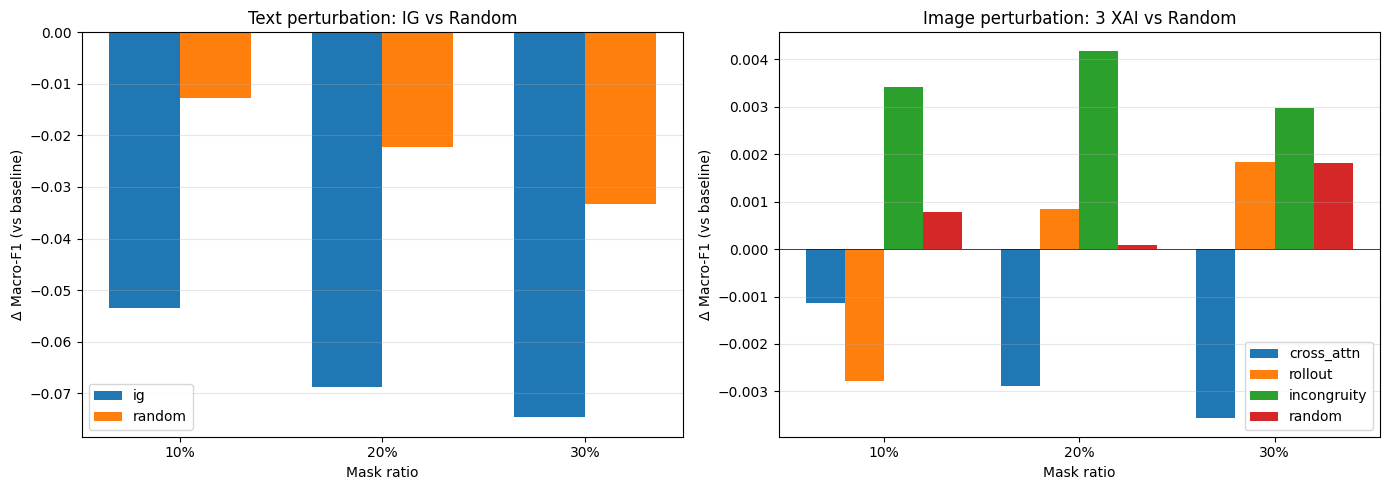

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Text
methods_text = ["ig", "random"]
levels = [10, 20, 30]
x = np.arange(len(levels))
w = 0.35
for i, m in enumerate(methods_text):
    deltas = [results_text[f"{m}_{lv}"]["macro_f1"] - baseline["macro_f1"] for lv in levels]
    axes[0].bar(x + i*w, deltas, w, label=m)
axes[0].set_xticks(x + w/2)
axes[0].set_xticklabels([f"{lv}%" for lv in levels])
axes[0].set_xlabel("Mask ratio")
axes[0].set_ylabel("Δ Macro-F1 (vs baseline)")
axes[0].set_title("Text perturbation: IG vs Random")
axes[0].axhline(0, color="black", linewidth=0.5)
axes[0].legend()
axes[0].grid(axis="y", alpha=0.3)

# Image
methods_img = ["cross_attn", "rollout", "incongruity", "random"]
x = np.arange(len(levels))
w = 0.20
for i, m in enumerate(methods_img):
    deltas = [results_image[f"{m}_{lv}"]["macro_f1"] - baseline["macro_f1"] for lv in levels]
    axes[1].bar(x + i*w, deltas, w, label=m)
axes[1].set_xticks(x + 1.5*w)
axes[1].set_xticklabels([f"{lv}%" for lv in levels])
axes[1].set_xlabel("Mask ratio")
axes[1].set_ylabel("Δ Macro-F1 (vs baseline)")
axes[1].set_title("Image perturbation: 3 XAI vs Random")
axes[1].axhline(0, color="black", linewidth=0.5)
axes[1].legend()
axes[1].grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "perturbation_bars.png", dpi=120, bbox_inches="tight")
plt.show()

In [17]:
final_results = {
    "exp_id":   CONFIG["exp_id"],
    "ckpt":     str(CKPT_PATH),
    "baseline": baseline,
    "text":     results_text,
    "image":    results_image,
    "config":   {k: (str(v) if isinstance(v, Path) else v) for k, v in CONFIG.items()},
}
with open(OUTPUT_DIR / "perturbation_results.json", "w") as f:
    json.dump(final_results, f, indent=2)

df_text.to_csv(OUTPUT_DIR / "perturbation_text.csv", index=False)
df_img.to_csv(OUTPUT_DIR / "perturbation_image.csv", index=False)

print(f"\nSaved:")
print(f"  {OUTPUT_DIR/'perturbation_results.json'}")
print(f"  {OUTPUT_DIR/'perturbation_text.csv'}")
print(f"  {OUTPUT_DIR/'perturbation_image.csv'}")
print(f"  {OUTPUT_DIR/'perturbation_bars.png'}")


Saved:
  /kaggle/working/xai_2B1_perturbation/perturbation_results.json
  /kaggle/working/xai_2B1_perturbation/perturbation_text.csv
  /kaggle/working/xai_2B1_perturbation/perturbation_image.csv
  /kaggle/working/xai_2B1_perturbation/perturbation_bars.png


In [18]:
print(f"\n{'='*72}\nKOMPONEN 2B.1 (PERTURBATION TEST) DONE\n{'='*72}")
print(f"Baseline Macro-F1: {baseline['macro_f1']:.4f}\n")

print("KIRIM BLOK INI KE CHAT:\n")
print("--- TEXT (IG vs Random) ---")
print(df_text[["method","mask_pct","delta_f1","delta_hate_r"]].to_string(index=False))
print("\n--- IMAGE (3 XAI vs Random) ---")
print(df_img[["method","mask_pct","delta_f1","delta_hate_r"]].to_string(index=False))
print(f"\nArtifacts: {OUTPUT_DIR}")


KOMPONEN 2B.1 (PERTURBATION TEST) DONE
Baseline Macro-F1: 0.7967

KIRIM BLOK INI KE CHAT:

--- TEXT (IG vs Random) ---
method  mask_pct  delta_f1  delta_hate_r
    ig        10 -0.053440     -0.146974
    ig        20 -0.068734     -0.144092
    ig        30 -0.074716     -0.141210
random        10 -0.012683     -0.002882
random        20 -0.022310     -0.014409
random        30 -0.033310     -0.011527

--- IMAGE (3 XAI vs Random) ---
     method  mask_pct  delta_f1  delta_hate_r
 cross_attn        10 -0.001130      0.008646
 cross_attn        20 -0.002876      0.000000
 cross_attn        30 -0.003568      0.002882
    rollout        10 -0.002785      0.011527
    rollout        20  0.000846      0.020173
    rollout        30  0.001825      0.031700
incongruity        10  0.003410      0.005764
incongruity        20  0.004181      0.014409
incongruity        30  0.002965      0.011527
     random        10  0.000788      0.008646
     random        20  0.000087      0.011527
     ran